# Notebook 03 — Reconocimiento facial: one-shot, few-shot y zero-shot

**Curso:** Deep Learning – Conceptos · Especialización en Inteligencia Artificial · Universidad de Cundinamarca  
**Actividad:** R2-A1-S10 Redes Neuronales V (semana 10: reconocimiento de rostros)  
**Autor:** Juan Pablo Cristancho Tula

Llegó el momento de probar el modelo con mis propias fotos. Uso el codificador que entrené en el Notebook 02 y el
dataset que preparé en el Notebook 01. Vale la pena aclarar dos cosas: **ninguna de las dos personas de mi dataset
participó en el entrenamiento**, y el modelo **no se vuelve a entrenar** aquí. Lo único que hago es calcular embeddings
y comparar distancias.

| Concepto | Qué significa | Cómo lo pruebo |
|---|---|---|
| **One-shot learning** | reconocer a alguien a partir de **una sola** foto | registro 1 foto por persona y verifico las demás contra ella |
| **Few-shot learning** | reconocer con **pocas** fotos (K = 2, 3, 5) | la galería guarda el promedio de K embeddings de cada persona (prototipo) |
| **Zero-shot learning** | reconocer clases de las que no se tiene **ningún** ejemplo de entrenamiento | el modelo verifica a personas que nunca vio al entrenar y rechaza a quien no está registrado |

Sobre *zero-shot* quiero ser preciso: en sentido estricto se refiere a reconocer clases sin ningún ejemplo,
apoyándose en información adicional como atributos o descripciones de texto. En reconocimiento facial con métricas, lo
equivalente es que la forma de medir parecido que la red aprendió con LFW **sirve sin reentrenar** para personas que
no estaban en el entrenamiento, y que alguien que no está registrado (cero fotos en la galería) debe quedar como
"desconocido".

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Juanpatula2361/Taller-Redes-Neuronales-V/blob/main/notebooks/03_reconocimiento_one_few_zero_shot.ipynb)

In [1]:
# ============================================================
# 0. Configuración
# ============================================================
import os
CONFIG = {
    "USAR_DRIVE": True,
    "CARPETA_BASE": "/content/drive/MyDrive/Redes_Neuronales_V",
    "REPO_URL": "https://github.com/Juanpatula2361/Taller-Redes-Neuronales-V.git",
    "K_VALORES": [1, 2, 3, 5],   # imágenes de enrolamiento por persona (few-shot)
    "REPETICIONES": 30,          # sorteos aleatorios de la galería por cada K
    "N_DESCONOCIDOS": 300,       # rostros de LFW (prueba) usados como personas no enroladas
    "DIFUMINAR_DESCONOCIDOS": True,
    "SEMILLA": 42,
}
BASE = CONFIG["CARPETA_BASE"]
PROC = os.path.join(BASE, "dataset_procesado")
DEMO = os.path.join(BASE, "fotos_demo")        # fotos nuevas, no usadas en el dataset
RES = os.path.join(BASE, "results")
CACHE = os.path.join(BASE, "cache")
MODELOS = os.path.join(BASE, "modelos")
CARPETAS = [RES, DEMO]

In [2]:
# ============================================================
# Configuración del entorno: Drive, dependencias y módulo de preprocesamiento
# ============================================================
import sys, json, time, subprocess, warnings
warnings.filterwarnings("ignore")
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB and CONFIG["USAR_DRIVE"]:
    from google.colab import drive
    drive.mount("/content/drive")

if EN_COLAB:
    # MTCNN (detector facial) y lectores de HEIC (iPhone) y DNG (RAW)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mtcnn==1.0.0", "pillow-heif", "rawpy"], check=True)
    if not os.path.isdir("/content/Taller-Redes-Neuronales-V"):
        subprocess.run(["git", "clone", "-q", CONFIG["REPO_URL"], "/content/Taller-Redes-Neuronales-V"])

# El código de preprocesamiento está en scripts/preprocesamiento_facial.py (un solo origen para los 3 notebooks)
for ruta in ["/content/Taller-Redes-Neuronales-V/scripts", os.path.join(BASE, "scripts"),
             os.path.abspath("../scripts"), os.path.abspath("scripts")]:
    if os.path.isfile(os.path.join(ruta, "preprocesamiento_facial.py")):
        sys.path.insert(0, ruta)
        break
else:
    raise FileNotFoundError("No se encontró scripts/preprocesamiento_facial.py: suba el repositorio a GitHub "
                            "o copie la carpeta scripts/ dentro de CARPETA_BASE.")
import preprocesamiento_facial as pf

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
for carpeta in CARPETAS:
    os.makedirs(carpeta, exist_ok=True)
print("Colab:", EN_COLAB, "| carpeta base:", BASE)

import tensorflow as tf
import keras
from scipy.spatial.distance import cdist
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(CONFIG["SEMILLA"])


@keras.saving.register_keras_serializable(package="rn5")
class DistanciaEuclidea(keras.layers.Layer):
    def call(self, a, b):
        return keras.ops.sqrt(keras.ops.sum(keras.ops.square(a - b), axis=-1, keepdims=True) + 1e-12)


codificador = keras.models.load_model(os.path.join(MODELOS, "codificador_facial.keras"), compile=False)
with open(os.path.join(MODELOS, "metadatos.json")) as f:
    meta = json.load(f)
UMBRAL, TAM = meta["umbral"], meta["tam"]
print(f"Codificador cargado | umbral τ = {UMBRAL:.4f}")

def embeddings(X, lote=64):
    return codificador.predict(X.astype("float32"), batch_size=lote, verbose=0)

# Dataset propio (Notebook 01) y rostros desconocidos (identidades de prueba de LFW, nunca entrenadas)
X_prop, y_prop, nombres, rutas = pf.cargar_dataset_procesado(PROC)
lfw = np.load(os.path.join(CACHE, meta.get("cache_lfw", f"lfw_alineado_{TAM}.npz")), allow_pickle=True)
m = np.isin(lfw["y"], meta["ids_prueba"])
idx_desc = rng.choice(np.flatnonzero(m), min(CONFIG["N_DESCONOCIDOS"], m.sum()), replace=False)
X_desc = lfw["X"][idx_desc]
E_prop, E_desc = embeddings(X_prop), embeddings(X_desc)
archivos = [os.path.basename(r) for r in rutas]
print(f"Dataset propio: {len(X_prop)} rostros de {len(nombres)} persona(s): " +
      ", ".join(f"{n} ({(y_prop == i).sum()})" for i, n in enumerate(nombres)))
print(f"Rostros desconocidos (LFW): {len(X_desc)}")

Mounted at /content/drive
Colab: True | carpeta base: /content/drive/MyDrive/Redes_Neuronales_V
Codificador cargado | umbral τ = 1.1214
Dataset propio: 17 rostros de 2 persona(s): persona_01 (9), persona_02 (8)
Rostros desconocidos (LFW): 300


## 1. Matriz de distancias de mi dataset

Cada celda muestra la distancia entre los embeddings de dos fotos. Si el modelo funciona bien, los bloques de la
diagonal (fotos de la misma persona) deberían tener distancias por debajo del umbral τ, y los bloques de fuera de la
diagonal (personas distintas), distancias por encima. Es la forma más directa de ver de un vistazo si la red separa a
las dos personas.

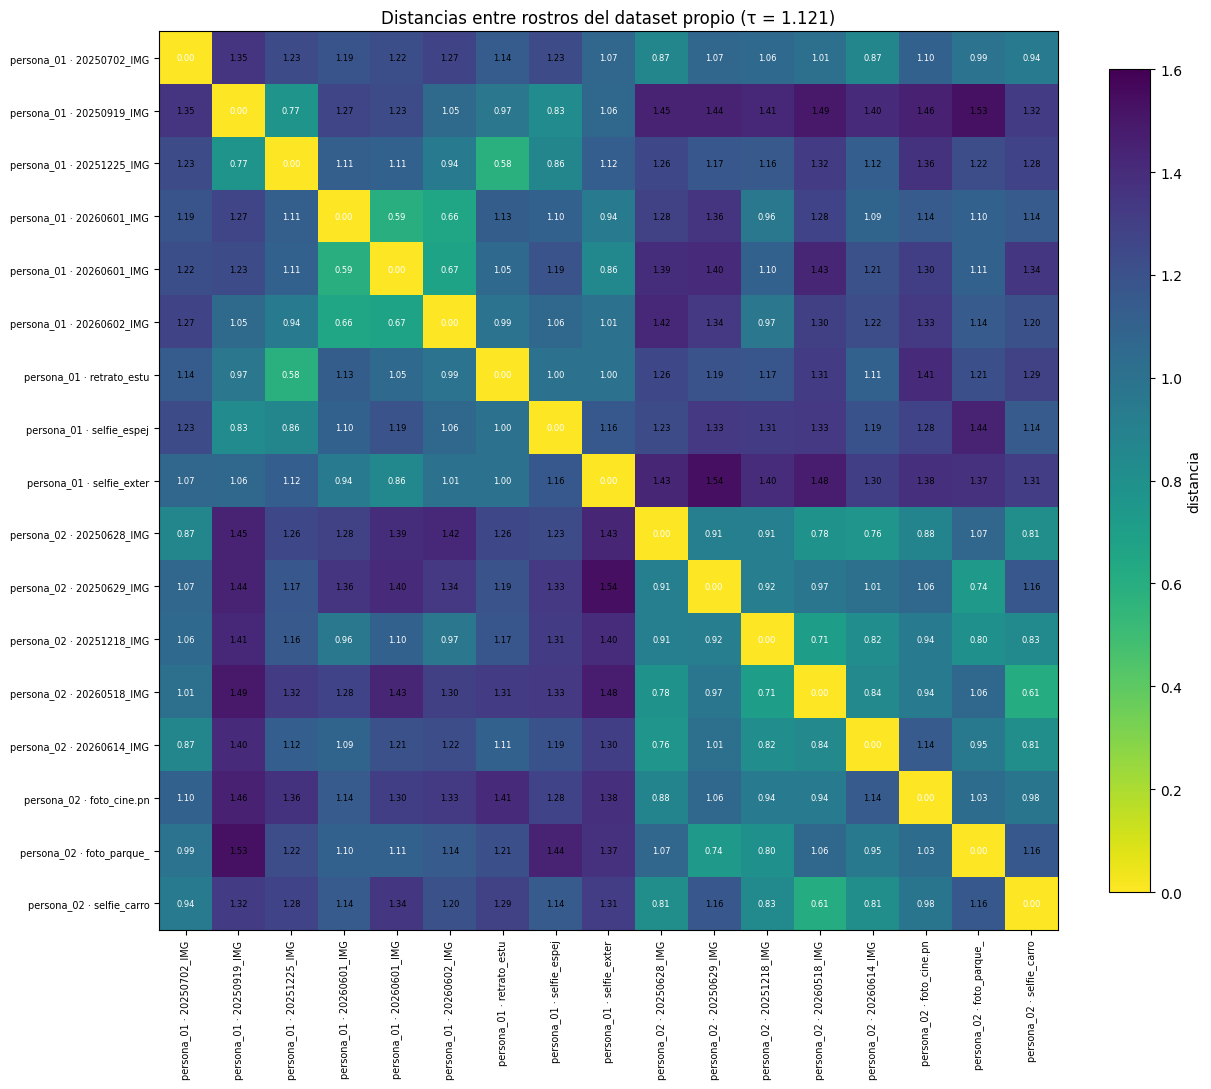

In [3]:
# ============================================================
# 1. Matriz de distancias entre todas las fotos propias
# ============================================================
D = cdist(E_prop, E_prop)
etq = [f"{nombres[y][:10]} · {a[:12]}" for y, a in zip(y_prop, archivos)]
fig, ax = plt.subplots(figsize=(0.55 * len(D) + 3, 0.5 * len(D) + 2.5))
im = ax.imshow(D, cmap="viridis_r", vmin=0, vmax=max(1.6, D.max()))
ax.set_xticks(range(len(D))); ax.set_xticklabels(etq, rotation=90, fontsize=7)
ax.set_yticks(range(len(D))); ax.set_yticklabels(etq, fontsize=7)
if len(D) <= 30:
    for i in range(len(D)):
        for j in range(len(D)):
            ax.text(j, i, f"{D[i, j]:.2f}", ha="center", va="center", fontsize=6,
                    color="white" if D[i, j] < UMBRAL else "black")
plt.colorbar(im, fraction=0.04, label="distancia")
ax.set_title(f"Distancias entre rostros del dataset propio (τ = {UMBRAL:.3f})")
plt.tight_layout(); plt.savefig(f"{RES}/03_matriz_distancias.png", dpi=130); plt.show()

## 2. One-shot: verificación con una sola foto de referencia

Para cada persona registro **una sola foto**, la de mejor calidad según el registro del Notebook 01 (mayor confianza de
detección y mayor nitidez), y la comparo contra el resto de sus fotos y contra rostros de personas desconocidas. Es el
escenario más exigente y también el más parecido a la vida real: cuando alguien registra su cara en una aplicación,
normalmente lo hace con una sola foto.

,persona,referencia,consulta,distancia,decision
0,persona_01,retrato_estudio.png,20250702_IMG_0303.png,1.1367,rechazada
1,persona_01,retrato_estudio.png,20250919_IMG_1780.png,0.9678,aceptada
2,persona_01,retrato_estudio.png,20251225_IMG_2983.png,0.5822,aceptada
3,persona_01,retrato_estudio.png,20260601_IMG_5859.png,1.1296,rechazada
4,persona_01,retrato_estudio.png,20260601_IMG_5860.png,1.0527,aceptada
5,persona_01,retrato_estudio.png,20260602_IMG_5873.png,0.9899,aceptada
6,persona_01,retrato_estudio.png,selfie_espejo_amarillo.png,1.0015,aceptada
7,persona_01,retrato_estudio.png,selfie_exterior_gorra.png,0.9965,aceptada
8,persona_02,foto_cine.png,20250628_IMG_0175.png,0.8800,aceptada
9,persona_02,foto_cine.png,20250629_IMG_0221.png,1.0595,aceptada


{'aceptacion_genuinos': 0.8, 'falsa_aceptacion_desconocidos': 0.1833, 'dist_media_genuinos': 0.9884, 'dist_media_desconocidos': 1.2616}


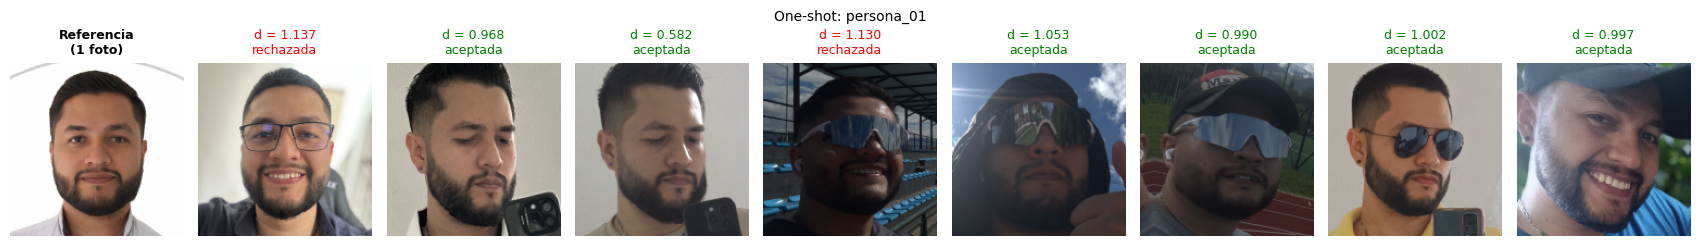

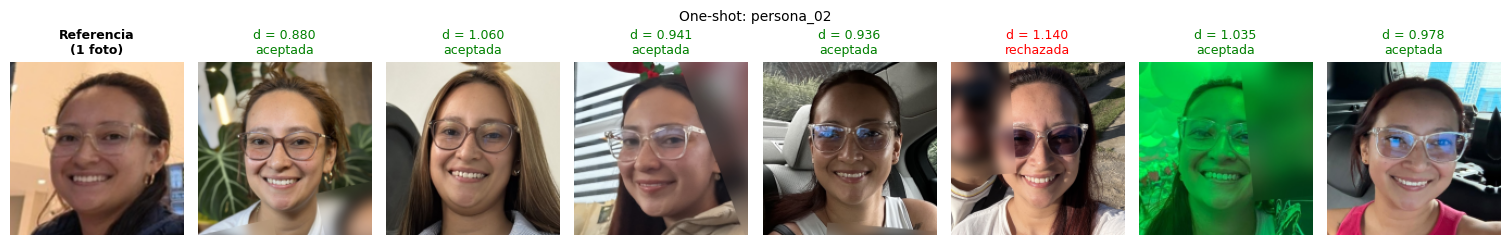

In [4]:
# ============================================================
# 2. One-shot
# ============================================================
registro = pd.read_csv(os.path.join(RES, "01_registro_preprocesamiento.csv"))
registro["base"] = registro["archivo"].str.rsplit(".", n=1).str[0]
filas, referencias = [], {}
for i, nombre in enumerate(nombres):
    idx = np.flatnonzero(y_prop == i)
    calidad = registro[registro["persona"] == nombre].set_index("base")
    puntaje = [calidad.loc[os.path.splitext(archivos[k])[0], ["confianza", "nitidez"]].tolist()
               if os.path.splitext(archivos[k])[0] in calidad.index else [0, 0] for k in idx]
    ref = idx[int(np.lexsort(np.array(puntaje).T[::-1])[-1])]
    referencias[nombre] = ref
    for k in idx:
        if k == ref:
            continue
        d = float(np.linalg.norm(E_prop[k] - E_prop[ref]))
        filas.append({"persona": nombre, "referencia": archivos[ref], "consulta": archivos[k],
                      "distancia": round(d, 4), "decision": "aceptada" if d < UMBRAL else "rechazada"})
one_shot = pd.DataFrame(filas)
display(one_shot)
d_desc = cdist(E_desc, E_prop[list(referencias.values())]).min(axis=1)
res_one = {
    "aceptacion_genuinos": float((one_shot["distancia"] < UMBRAL).mean()) if len(one_shot) else None,
    "falsa_aceptacion_desconocidos": float((d_desc < UMBRAL).mean()),
    "dist_media_genuinos": float(one_shot["distancia"].mean()) if len(one_shot) else None,
    "dist_media_desconocidos": float(d_desc.mean()),
}
print({k: (round(v, 4) if v is not None else None) for k, v in res_one.items()})

# Figura: referencia y consultas con su distancia
for nombre, ref in referencias.items():
    cons = one_shot[one_shot["persona"] == nombre]
    n = len(cons) + 1
    fig, axes = plt.subplots(1, n, figsize=(1.9 * n, 2.6))
    axes = np.atleast_1d(axes)
    axes[0].imshow(X_prop[ref]); axes[0].set_title("Referencia\n(1 foto)", fontsize=9, fontweight="bold")
    for ax, (_, f) in zip(axes[1:], cons.iterrows()):
        ax.imshow(X_prop[archivos.index(f["consulta"])])
        ax.set_title(f"d = {f['distancia']:.3f}\n{f['decision']}", fontsize=9,
                     color="green" if f["decision"] == "aceptada" else "red")
    for ax in axes:
        ax.axis("off")
    plt.suptitle(f"One-shot: {nombre}", fontsize=10)
    plt.tight_layout(); plt.savefig(f"{RES}/03_one_shot_{nombre}.png", dpi=130); plt.show()

## 3. Few-shot: identificación con una galería de K fotos

Aquí la galería guarda por cada persona un **prototipo**: el promedio de K embeddings, normalizado. Cuando llega una
foto nueva, la asigno a la persona con el prototipo más cercano, pero solo si la distancia es menor que τ; si no,
respondo "desconocido". A esto se le llama identificación de **conjunto abierto**, porque el sistema debe admitir que
no conoce a alguien en lugar de forzar una respuesta.

Como el resultado depende de qué fotos caen en la galería, repito el sorteo 30 veces para cada K y reporto el
promedio y la desviación estándar de:

- **Identificación correcta**: fotos de personas registradas que se asignan a la persona correcta.
- **Falsa aceptación**: rostros desconocidos que el sistema confunde con alguna persona registrada.

,K,identificacion_correcta_media,falsa_aceptacion_media,rechazo_genuinos_media,identificacion_correcta_std,falsa_aceptacion_std,rechazo_genuinos_std
0,1,0.7556,0.1956,0.1378,0.1479,0.0759,0.1134
1,2,0.8923,0.1550,0.0282,0.0592,0.0505,0.0514
2,3,0.9182,0.1512,0.0121,0.0498,0.0552,0.0314
3,5,0.9190,0.1503,0.0000,0.0720,0.0326,0.0000


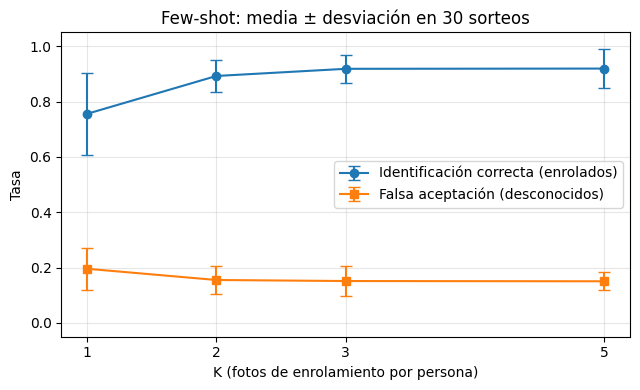

In [5]:
# ============================================================
# 3. Few-shot (K = 1, 2, 3, 5)
# ============================================================
def evaluar_galeria(K, semilla):
    g = np.random.default_rng(semilla)
    protos, consultas, verdad = [], [], []
    for i in range(len(nombres)):
        idx = np.flatnonzero(y_prop == i)
        if len(idx) <= K:
            return None
        enrol = g.choice(idx, K, replace=False)
        p = E_prop[enrol].mean(axis=0)
        protos.append(p / np.linalg.norm(p))
        resto = np.setdiff1d(idx, enrol)
        consultas.append(resto); verdad += [i] * len(resto)
    protos = np.stack(protos)
    Dq = cdist(E_prop[np.concatenate(consultas)], protos)
    pred = np.where(Dq.min(axis=1) < UMBRAL, Dq.argmin(axis=1), -1)
    Du = cdist(E_desc, protos).min(axis=1)
    return {"identificacion_correcta": float(np.mean(pred == np.array(verdad))),
            "falsa_aceptacion": float(np.mean(Du < UMBRAL)),
            "rechazo_genuinos": float(np.mean(pred == -1))}


filas = []
for K in CONFIG["K_VALORES"]:
    corridas = [r for r in (evaluar_galeria(K, s) for s in range(CONFIG["REPETICIONES"])) if r]
    if not corridas:
        print(f"K = {K}: no hay suficientes fotos por persona"); continue
    df = pd.DataFrame(corridas)
    filas.append({"K": K, **{f"{c}_media": df[c].mean() for c in df}, **{f"{c}_std": df[c].std() for c in df}})
few_shot = pd.DataFrame(filas)
display(few_shot.round(4))

plt.figure(figsize=(6.5, 4))
plt.errorbar(few_shot["K"], few_shot["identificacion_correcta_media"], yerr=few_shot["identificacion_correcta_std"],
             marker="o", capsize=4, label="Identificación correcta (enrolados)")
plt.errorbar(few_shot["K"], few_shot["falsa_aceptacion_media"], yerr=few_shot["falsa_aceptacion_std"],
             marker="s", capsize=4, label="Falsa aceptación (desconocidos)")
plt.xlabel("K (fotos de enrolamiento por persona)"); plt.ylabel("Tasa"); plt.ylim(-0.05, 1.05)
plt.xticks(few_shot["K"]); plt.grid(alpha=.3); plt.legend()
plt.title(f"Few-shot: media ± desviación en {CONFIG['REPETICIONES']} sorteos")
plt.tight_layout(); plt.savefig(f"{RES}/03_few_shot.png", dpi=130); plt.show()

## 4. Zero-shot: generalización a personas nunca vistas

En esta prueba mido la verificación uno a uno sobre mi dataset sin ajustar nada del modelo. Los pares genuinos son
todas las parejas de fotos de una misma persona, y los impostores son parejas entre una foto mía (o de la otra persona)
y un rostro de las personas de prueba de LFW, además de las parejas entre las dos personas de mi dataset. Si el AUC
sale alto, significa que lo que la red aprendió con LFW se transfiere bien a personas que nunca vio.

{'pares_genuinos': 64, 'pares_impostores': 5172, 'auc': 0.9377, 'aceptacion_genuinos': 0.7656, 'falsa_aceptacion': 0.0926, 'dist_media_genuinos': 0.9782, 'dist_media_impostores': 1.3693}


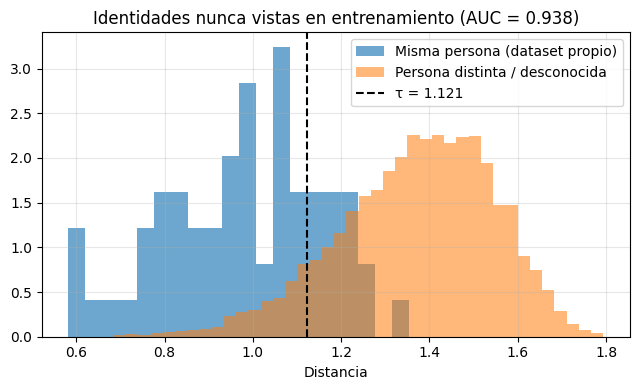

In [6]:
# ============================================================
# 4. Verificación sobre identidades no vistas (sin reentrenar)
# ============================================================
gen = [np.linalg.norm(E_prop[i] - E_prop[j]) for i in range(len(E_prop)) for j in range(i + 1, len(E_prop))
       if y_prop[i] == y_prop[j]]
imp = [np.linalg.norm(E_prop[i] - E_prop[j]) for i in range(len(E_prop)) for j in range(i + 1, len(E_prop))
       if y_prop[i] != y_prop[j]]
imp += list(cdist(E_prop, E_desc).ravel())
gen, imp = np.array(gen), np.array(imp)
etiquetas = np.r_[np.ones(len(gen)), np.zeros(len(imp))]
dist = np.r_[gen, imp]
res_zero = {
    "pares_genuinos": int(len(gen)), "pares_impostores": int(len(imp)),
    "auc": float(roc_auc_score(etiquetas, -dist)),
    "aceptacion_genuinos": float(np.mean(gen < UMBRAL)),
    "falsa_aceptacion": float(np.mean(imp < UMBRAL)),
    "dist_media_genuinos": float(gen.mean()), "dist_media_impostores": float(imp.mean()),
}
print({k: round(v, 4) if isinstance(v, float) else v for k, v in res_zero.items()})
plt.figure(figsize=(6.5, 4))
plt.hist(gen, bins=20, alpha=.65, density=True, label="Misma persona (dataset propio)")
plt.hist(imp, bins=40, alpha=.55, density=True, label="Persona distinta / desconocida")
plt.axvline(UMBRAL, color="k", ls="--", label=f"τ = {UMBRAL:.3f}")
plt.xlabel("Distancia"); plt.legend(); plt.grid(alpha=.3)
plt.title(f"Identidades nunca vistas en entrenamiento (AUC = {res_zero['auc']:.3f})")
plt.tight_layout(); plt.savefig(f"{RES}/03_zero_shot_distancias.png", dpi=130); plt.show()

## 5. Demostración con fotos nuevas

Para cerrar uso fotos que no hacen parte del dataset (carpeta `fotos_demo/`). El sistema detecta cada rostro, busca
el prototipo más cercano en la galería y escribe el nombre y la distancia. Si la distancia supera τ, marca el rostro
como **desconocido** y lo difumina, porque no tengo autorización para mostrar a esa persona.

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


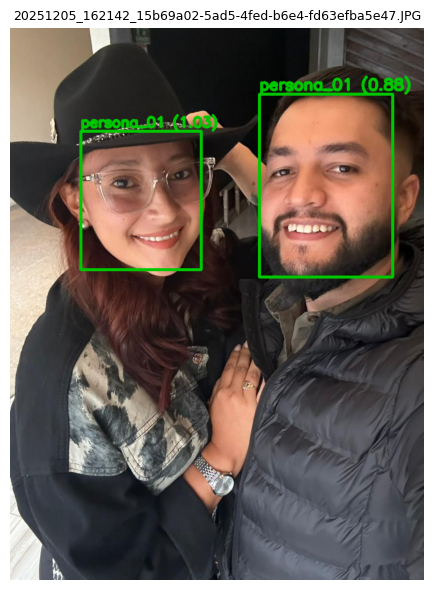

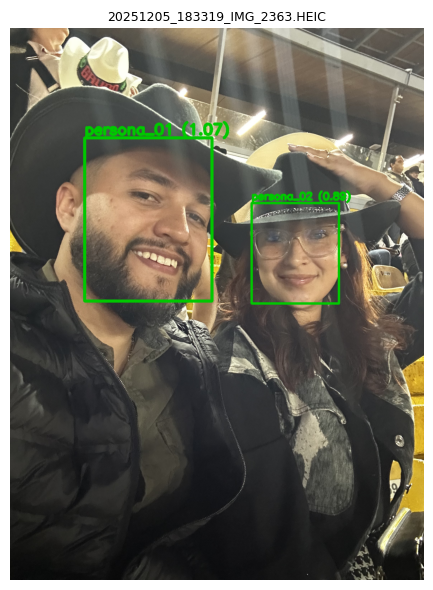

,foto,prediccion,distancia
0,20251205_162142_15b69a02-5ad5-4fed-b6e4-fd63ef...,persona_01,0.8811
1,20251205_162142_15b69a02-5ad5-4fed-b6e4-fd63ef...,persona_01,1.0322
2,20251205_183319_IMG_2363.HEIC,persona_01,1.0651
3,20251205_183319_IMG_2363.HEIC,persona_02,0.8907


In [7]:
# ============================================================
# 5. Reconocimiento en fotos nuevas
# ============================================================
detector = pf.crear_detector()
protos = np.stack([E_prop[y_prop == i].mean(axis=0) for i in range(len(nombres))])
protos /= np.linalg.norm(protos, axis=1, keepdims=True)

def reconocer(ruta):
    img = pf.cargar_imagen(ruta)
    rostros = pf.procesar_todos_los_rostros(img, detector, tam=TAM)
    if not rostros:
        img_e = pf.escalar(img, 0.5)
        rostros = [pf.ResultadoRostro(r.recorte, [int(v / 0.5) for v in r.box], r.confianza, r.angulo, 1)
                   for r in pf.procesar_todos_los_rostros(img_e, detector, tam=TAM)]
    salida, detalles = img.copy(), []
    if rostros:
        E = embeddings(np.stack([r.recorte for r in rostros]))
        Dg = cdist(E, protos)
        for r, fila in zip(rostros, Dg):
            k, d = int(fila.argmin()), float(fila.min())
            conocido = d < UMBRAL
            etiqueta = f"{nombres[k]} ({d:.2f})" if conocido else f"Desconocido ({d:.2f})"
            if not conocido and CONFIG["DIFUMINAR_DESCONOCIDOS"]:
                salida = pf.difuminar_region(salida, r.box)
            x, y, w, h = r.box
            color = (0, 200, 0) if conocido else (220, 0, 0)
            grosor = max(2, w // 50)
            cv2.rectangle(salida, (x, y), (x + w, y + h), color, grosor)
            cv2.putText(salida, etiqueta, (x, max(20, y - 10)), cv2.FONT_HERSHEY_SIMPLEX, max(0.6, w / 260), color, grosor)
            detalles.append({"foto": os.path.basename(ruta), "prediccion": nombres[k] if conocido else "desconocido",
                             "distancia": round(d, 4)})
    return salida, detalles


fotos = pf.listar_imagenes(DEMO)
if not fotos:
    print(f"No hay fotos en {DEMO}. Copie allí 2 o 3 fotos nuevas (no usadas en el dataset) y vuelva a ejecutar.")
demo = []
for n, ruta in enumerate(fotos[:6]):
    vis, det = reconocer(ruta)
    demo += det
    plt.figure(figsize=(6, 6)); plt.imshow(vis); plt.axis("off"); plt.title(os.path.basename(ruta), fontsize=9)
    plt.tight_layout(); plt.savefig(f"{RES}/03_demo_{n + 1}.png", dpi=120); plt.show()
if demo:
    display(pd.DataFrame(demo))

In [8]:
# ============================================================
# 6. Guardado de resultados para el informe
# ============================================================
resultado = {
    "umbral": UMBRAL, "personas": nombres,
    "fotos_por_persona": {n: int((y_prop == i).sum()) for i, n in enumerate(nombres)},
    "desconocidos_lfw": int(len(X_desc)),
    "one_shot": {"referencias": {n: archivos[k] for n, k in referencias.items()}, **res_one,
                 "detalle": one_shot.to_dict(orient="records")},
    "few_shot": few_shot.to_dict(orient="records"),
    "zero_shot": res_zero,
    "demo": demo,
}
with open(f"{RES}/03_metricas_reconocimiento.json", "w", encoding="utf-8") as f:
    json.dump(resultado, f, indent=2, ensure_ascii=False)
print("Resultados guardados en", RES)
print(sorted(os.listdir(RES)))

Resultados guardados en /content/drive/MyDrive/Redes_Neuronales_V/results
['01_alineacion.png', '01_clahe.png', '01_deteccion_mtcnn.png', '01_imagenes_originales.png', '01_registro_preprocesamiento.csv', '01_resumen_dataset.json', '01_rostros_procesados.png', '02_arquitectura_siamesa.png', '02_curvas_entrenamiento.png', '02_ejemplos_pares.png', '02_lote_pk_aumento.png', '02_metricas_siamesa.json', '02_muestras_lfw.png', '02_roc_y_distancias.png', '02_tsne_embeddings.png', '03_demo_1.png', '03_demo_2.png', '03_few_shot.png', '03_matriz_distancias.png', '03_metricas_reconocimiento.json', '03_one_shot_persona_01.png', '03_one_shot_persona_02.png', '03_zero_shot_distancias.png']
